# Sequential Ergodic Exploration using Tensor Train (2-D)

Reference: S. Shetty, J. Silvério, S. Calinon, "Ergodic Exploration using Tensor Train: Applications in Insertion Tasks" (E2T2), arXiv:2101.04428, and its notebook, whose structure this one follows.

E2T2 explores one fixed reference distribution. For a sequential task this notebook adds two things, each kept in TT format:
- an **expanding target**: the reference holds only the taught datapoints up to the current phase plus a lead;
- a **forgetting statistic**: coverage fades, so after a failure the earlier stages count as uncovered again;

The task is a **peg-slide**: insert the peg into the slot of a block from above, then push the block along to the goal. The push is physically impossible before the insertion has succeeded, and the taught motion never crosses or retraces itself, so progress along it is continuous. In each sequence of trials the block sits further from where it was taught than the slot's clearance, so the taught motion misses the slot.

A memory of failures across trials (negative target mass, marks in the statistic) is out of scope here: every form of it tried so far made the law worse.

In [1]:
import time
from dataclasses import dataclass
from multiprocessing import Pool

import numpy as np
import tt
from matplotlib import pyplot as plt
from matplotlib.patches import Rectangle
from scipy.optimize import minimize_scalar
from scipy.special import logsumexp
from tt.cross import rect_cross

### State space
The world is $[0, 1]^d$, and the law's cube $\Omega = [a, a + L]^d$ extends beyond it by a margin $m$, $a = -m$, $L = 1 + 2m$, with $K$ cosine functions per axis and $K^d$ coefficients. The margin is needed because every cosine $\phi_k$ has zero slope at the cube's faces: a state on a face gets no push off it from the law, and at a corner $\mathbf{b} = \mathbf{0}$. E2T2 keeps the state away from the faces with `pull2centre`; here the faces lie outside the world, so the world's own walls are all the state ever touches. $m = 1 / (2(K-1))$ is a quarter of the finest mode's period: at that distance from a face its slope peaks.

In [2]:
d = 2  # dimension of the state space
K = 10  # basis functions per axis
WORLD = 1.0  # side of the world
MARGIN = WORLD / (2 * (K - 1))
CUBE_LO, L = -MARGIN, WORLD + 2 * MARGIN  # the law's cube [CUBE_LO, CUBE_LO + L]
print("Number of Fourier coefficients:", K**d)

Number of Fourier coefficients: 100


### Fourier basis and its gradient in TT format
$$\begin{align*}
\phi_k(x) &= \cos\Big(\frac{\pi k (x - a)}{L}\Big), \quad k \in \{0, \ldots, K-1\}, \\
\mathbf{\Phi}(\mathbf{x}) &= \boldsymbol{\phi}(x_1) \circ \cdots \circ \boldsymbol{\phi}(x_d), \\
\nabla_i \mathbf{\Phi}(\mathbf{x}) &= \boldsymbol{\phi}(x_1) \circ \cdots \circ \frac{\partial \boldsymbol{\phi}(x_i)}{\partial x} \circ \cdots \circ \boldsymbol{\phi}(x_d).
\end{align*}$$
$\pi$ rather than the paper's $2\pi$, as in the E2T2 code: with $2\pi$ every basis function is symmetric about $L/2$. Both are rank-1 TTs.

In [3]:
def Phi(y):  # (K,)
    return np.cos(np.pi * (y - CUBE_LO) * np.arange(K) / L)


def DPhi(y):  # (K,)
    return (-np.pi / L) * np.arange(K) * np.sin(np.pi * (y - CUBE_LO) * np.arange(K) / L)


def tt_phi_dphi(x):
    cores = [Phi(xi).reshape(1, -1, 1) for xi in x]
    dcores = [DPhi(xi).reshape(1, -1, 1) for xi in x]
    tt_phi = tt.vector.from_list(cores)
    tt_dphi = [tt.vector.from_list([*cores[:i], dcores[i], *cores[i + 1 :]]) for i in range(len(x))]
    return tt_phi, tt_dphi

### The task: a peg-slide
All lengths in cube units. A block of half-width $0.075$ stands on the floor, $y \in [0, 0.20]$, centred at $c$. A slot of half-width $0.03$, open at the top, reaches down to $y = 0.05$. The peg tip is the end of a peg of half-width $0.01$, which is taken off every gap at the sides, so the clearance in the slot is $\pm 0.02$. In each sequence the block starts at $c_0 + \Delta$, where $c_0 = 0.23$ is where it was taught.

- **Barrier.** A wall at $x = 0.40$ stops the tip and the block until the tip has been within $0.015$ of the slot's floor. Then it is gone for good.
- **Push.** A tip in the slot carries the block sideways by its walls. The block never moves left of where it started, and it moves only through the slot.
- **Goal.** The block's centre and the tip both beyond $x = 0.80$.
- **Contact.** Faces stop the tip and let it slide along them.

`in_dead_end` is for the evaluation only, the law never sees it: the tip below the block's top beside the block, or against the barrier, while the barrier stands.

In [4]:
BLOCK_HALF, BLOCK_TOP = 0.075, 0.20
SLOT_HALF, SLOT_FLOOR = 0.03, 0.05
PEG = 0.01  # the peg's half-width
CLEAR = SLOT_HALF - PEG  # the tip's play either side of the slot's centre
INSERTED = 0.015  # the tip this close to the slot's floor removes the barrier
BARRIER_X = 0.40
C0 = 0.23  # the block's centre as taught
GOAL_X = 0.80
DT = 0.01  # s per step, 100 Hz
V_MAX, NOISE = 0.004, 0.007  # the plant: step cap, and uniform actuator noise per axis per step
MASTER = np.array([[C0, 0.45], [C0, 0.06], [0.85, 0.06]])


@dataclass
class Slide:
    offset: float = 0.0  # the block's start relative to where it was taught
    c: float = None  # the block's centre
    barrier: bool = True

    def __post_init__(self):
        self.home = C0 + self.offset
        self.c = self.home if self.c is None else self.c


def in_slot(world, x, y):
    # 1e-12: a tip clamped onto a slot wall is c +- CLEAR only up to round-off, and stays inside.
    return abs(x - world.c) <= CLEAR + 1e-12 and SLOT_FLOOR <= y < BLOCK_TOP


def free(world, x, y):
    in_block = abs(x - world.c) < BLOCK_HALF + PEG and y < BLOCK_TOP
    at_barrier = world.barrier and abs(x - BARRIER_X) < PEG
    return not at_barrier and (not in_block or in_slot(world, x, y))


def advance(world, a, b):
    # The furthest point towards b that the tip reaches from a before touching a face.
    if free(world, *b):
        return b
    lo, hi = 0.0, 1.0
    for _ in range(40):  # 2^-40 of a step: contact to round-off
        mid = 0.5 * (lo + hi)
        lo, hi = (mid, hi) if free(world, *(a + mid * (b - a))) else (lo, mid)
    return a + lo * (b - a)


def step(world, s, s_cmd):
    # The tip the world lets the robot reach from s towards s_cmd; moves the block if pushed.
    nx, ny = np.clip(s_cmd, 0.0, WORLD)
    x, y = s
    if in_slot(world, x, y):
        ny = max(ny, SLOT_FLOOR)
        world.barrier = world.barrier and ny > SLOT_FLOOR + INSERTED
        c_max = BARRIER_X - PEG - BLOCK_HALF if world.barrier else WORLD - BLOCK_HALF
        pushed = nx - np.clip(nx, world.c - CLEAR, world.c + CLEAR)
        world.c = float(np.clip(world.c + pushed, world.home, max(c_max, world.c)))
        return np.array([np.clip(nx, world.c - CLEAR, world.c + CLEAR), ny])
    # Outside the slot: up to the first contact, then the rest of the step along the face.
    p = advance(world, np.array([x, y]), np.array([nx, ny]))
    p = advance(world, p, np.array([nx, p[1]]))
    return advance(world, p, np.array([p[0], ny]))


def succeeded(world, s):
    return bool(s[0] > GOAL_X and world.c > GOAL_X)


def in_dead_end(world, s):
    beside = abs(s[0] - world.c) >= BLOCK_HALF + PEG and s[1] < BLOCK_TOP and s[0] < BARRIER_X
    return bool(world.barrier and (beside or abs(s[0] - BARRIER_X) < PEG + 0.02))


def replay(world, waypoints, n_steps, rng=None):
    # Follow the waypoints at V_MAX; with rng, through the plant's actuator noise.
    s, i, path = waypoints[0].copy(), 1, [waypoints[0].copy()]
    for _ in range(n_steps):
        if i == len(waypoints):  # a demonstration ends at its last waypoint, not at the goal's edge
            break
        to_go = waypoints[i] - s
        if np.linalg.norm(to_go) <= V_MAX:
            cmd, i = waypoints[i], i + 1
        else:
            cmd = s + V_MAX * to_go / np.linalg.norm(to_go)
        if rng is not None:
            cmd = cmd + rng.uniform(-NOISE, NOISE, d)
        s = step(world, s, cmd)
        path.append(s)
    return np.array(path)


def draw_world(ax, world):
    ax.add_patch(Rectangle((world.c - BLOCK_HALF, 0), 2 * BLOCK_HALF, BLOCK_TOP, color="0.6"))
    ax.add_patch(Rectangle((world.c - SLOT_HALF, SLOT_FLOOR), 2 * SLOT_HALF, BLOCK_TOP, color="w"))
    if world.barrier:
        ax.axvline(BARRIER_X, color="g", ls=":")
    ax.axvspan(GOAL_X, WORLD, color="g", alpha=0.1)
    ax.set(xlim=(0, WORLD), ylim=(0, WORLD), aspect="equal")

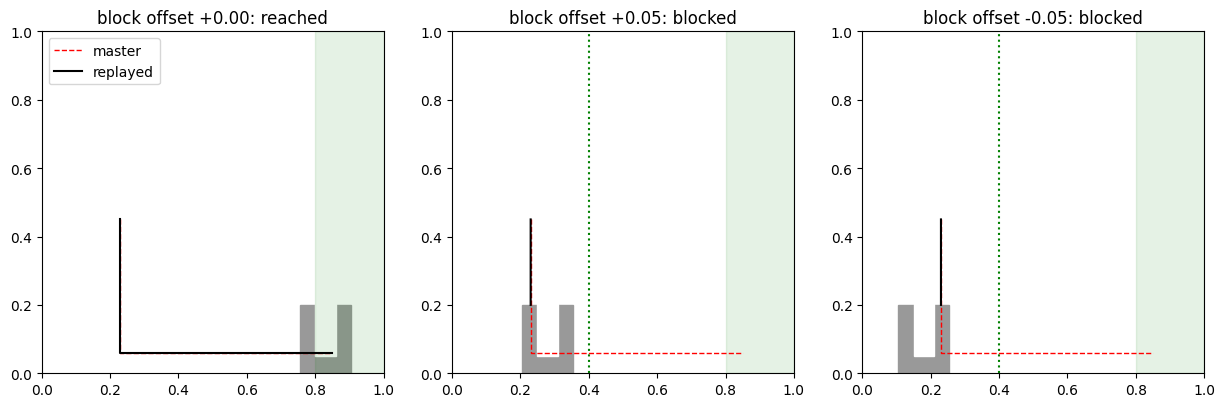

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, offset in zip(ax, (0.0, 0.05, -0.05), strict=True):
    world = Slide(offset)
    path = replay(world, MASTER, 3000)
    draw_world(a, world)  # as the replay left it
    a.plot(*MASTER.T, "r--", lw=1, label="master")
    a.plot(*path.T, "k", lw=1.5, label="replayed")
    a.set_title(
        f"block offset {offset:+.2f}: {'reached' if succeeded(world, path[-1]) else 'blocked'}"
    )
ax[0].legend()
plt.show()

### Demonstration
**Master.** The taught motion, resampled at $N_{\mathrm{m}} + 1$ points $\mathbf{m}_a$ equally spaced in arc length, with phase $\varphi_a = a / N_{\mathrm{m}}$ and length $S_{\mathrm{m}}$. It goes down into the slot and pushes right, never back over itself, so the phase rises continuously along it.

**Datapoints.** $N_{\mathrm{d}}$ executions of the task in the taught world, each from its own start and at its own height in the slot, through the plant's actuator noise. Every datapoint is a state one of them visited, so none lies inside the block or on the wrong side of the barrier. As in E2T2, where almost half the datapoints were taken inside the hole, importance is a count: $N_{\mathrm{p}}/2$ datapoints are drawn from all states and $N_{\mathrm{p}}/2$ from the insertion, the phases from the block's top to the slot's floor. Each datapoint is labelled with the phase of its nearest master sample, $\varphi_m = \varphi_{a^*}$, $a^* = \arg\min_a \|\mathbf{x}_m - \mathbf{m}_a\|$.

In [6]:
N_M = 400  # master samples
N_DEMOS, N_P = 8, 200

seg = np.linalg.norm(np.diff(MASTER, axis=0), axis=1)
S_m = seg.sum()
s_grid = np.linspace(0, S_m, N_M + 1)
knots = np.concatenate([[0], np.cumsum(seg)])
master = np.column_stack([np.interp(s_grid, knots, MASTER[:, i]) for i in range(d)])
phi_master = s_grid / S_m


def phase_label(X):  # (n, d) -> (n,), the phase of the nearest master sample
    return phi_master[np.linalg.norm(X[:, None] - master[None], axis=2).argmin(axis=1)]


rng = np.random.default_rng(1)
demos = []
for _ in range(N_DEMOS):
    y_push = SLOT_FLOOR + rng.uniform(0.003, INSERTED - 0.003)
    start = MASTER[0] + rng.uniform(-0.05, 0.05, d)
    waypoints = np.array([start, [C0 + rng.uniform(-PEG, PEG), y_push], [MASTER[-1, 0], y_push]])
    world = Slide()
    demos.append(replay(world, waypoints, 3000, rng))
    assert succeeded(world, demos[-1][-1])

states = np.concatenate(demos)
phi_states = phase_label(states)
insertion = (phi_states >= (MASTER[0, 1] - BLOCK_TOP) / S_m) & (
    phi_states <= (MASTER[0, 1] - MASTER[1, 1]) / S_m
)
first = rng.choice(len(states), N_P // 2, replace=False)
rest = rng.choice(np.setdiff1d(np.flatnonzero(insertion), first), N_P // 2, replace=False)
pick = np.concatenate([first, rest])
X_p, phi_p = states[pick], phi_states[pick]
print(f"S_m = {S_m:.3f}; {len(states)} states from {N_DEMOS} demonstrations; {N_P} datapoints")

S_m = 1.010; 2235 states from 8 demonstrations; 200 datapoints


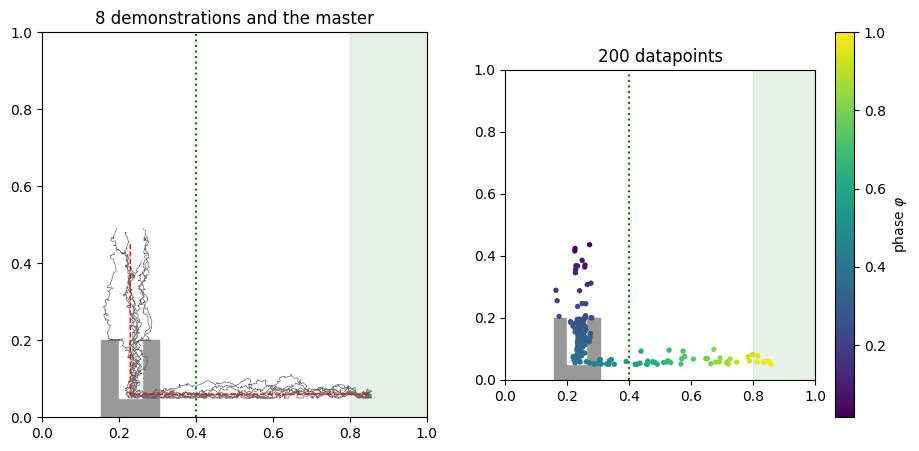

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 5))
for a in ax:
    draw_world(a, Slide())
for path_ in demos:
    ax[0].plot(*path_.T, "-", color="0.4", lw=0.5)
ax[0].plot(*master.T, "r--", lw=1)
ax[0].set_title(f"{N_DEMOS} demonstrations and the master")
sc = ax[1].scatter(*X_p.T, c=phi_p, s=8, cmap="viridis")
fig.colorbar(sc, ax=ax[1], label=r"phase $\varphi$")
ax[1].set_title(f"{N_P} datapoints")
plt.show()

### The expanding target
**Kernels.** Each datapoint $\mathbf{x}_m$ is an isotropic Gaussian of width $h$, **reflected at the cube's faces** (method of images), so it has mass exactly 1 inside $\Omega$:
$$g(y; \mu) = \sum_{n \in \mathbb{Z}} \big[\mathcal{N}(y;\, \mu + 2nL,\, h^2) + \mathcal{N}(y;\, 2a - \mu + 2nL,\, h^2)\big].$$
Unfolding the images onto the real line, $\int_a^{a+L} g(y;\mu)\,\phi_k(y)\,dy = \int_{\mathbb{R}} \mathcal{N}(y; \mu, h^2) \cos(\pi k (y - a) / L)\, dy$, so its coefficients are exact and separable,
$$\hat{\mathcal{W}}^{(m)}_{\mathbf{k}} = \prod_{i=1}^d c_{k_i}(x_{m,i}), \qquad c_k(\mu) = e^{-(\pi k h / L)^2 / 2} \cos(\pi k (\mu - a) / L),$$
a rank-1 TT per datapoint, with no TT-cross and no renormalisation.

**Width.** $h$ maximises the leave-one-out likelihood of the datapoints under their own kernel density, $\sum_m \log \frac{1}{N_{\mathrm{p}} - 1} \sum_{n \ne m} \prod_i g(x_{m,i}; x_{n,i})$.

**Expansion.** The target holds the datapoints up to a front one resolvable width ahead of the phase $\varphi$:
$$\hat{\mathcal{W}}(\varphi) = \sum_m w_m(\varphi)\, \hat{\mathcal{W}}^{(m)}, \qquad w_m(\varphi) \propto \sigma\Big(\frac{\varphi + \delta - \varphi_m}{\varepsilon}\Big), \qquad \sum_m w_m = 1,$$
with $\sigma$ the logistic function and $\delta = \varepsilon = \sigma_{\mathrm{f}} = \max(h,\ L / (K - 1)) / S_{\mathrm{m}}$. The law sees nothing narrower than $L / (K - 1)$, the half-period of its finest mode, so a front closer than that would add nothing it can see. E2T2's static target is $w_m = 1 / N_{\mathrm{p}}$. The sum is built as one TT with diagonal cores and rounded; at $d = 2$ its rank cannot exceed $K$, so the rounding loses nothing.

In [8]:
def g(y, mu, h):  # Gaussian reflected at the cube's faces, broadcast over y and mu
    n = 2 * L * np.arange(-2, 3)  # images beyond |n| = 2 lie more than 3L away
    images = np.concatenate([mu[..., None] + n, 2 * CUBE_LO - mu[..., None] + n], axis=-1)
    return np.exp(-((y[..., None] - images) ** 2) / (2 * h**2)).sum(-1) / (np.sqrt(2 * np.pi) * h)


def loo_log_likelihood(h):
    G = np.prod([g(X_p[:, None, i], X_p[None, :, i], h) for i in range(d)], axis=0)
    np.fill_diagonal(G, 0.0)
    return np.log(G.sum(axis=1) / (N_P - 1)).sum()


h = float(
    np.exp(
        minimize_scalar(
            lambda lh: -loo_log_likelihood(np.exp(lh)), bounds=np.log([1e-3, 0.3]), method="bounded"
        ).x
    )
)
sigma_f = max(h, L / (K - 1)) / S_m
delta = eps_f = sigma_f
C = [
    np.exp(-((np.pi * np.arange(K) * h / L) ** 2) / 2)
    * np.cos(np.pi * np.arange(K) * (X_p[:, [i]] - CUBE_LO) / L)
    for i in range(d)
]  # (N_P, K) per axis


def weights(phi):  # (N_P,), of sum 1
    w = 1.0 / (1.0 + np.exp(-(phi + delta - phi_p) / eps_f))
    return w / w.sum()


def tt_weighted_sum(
    rows, w
):  # rows: (M, K) per axis -> the TT of sum_m w_m rows_1[m] o ... o rows_d[m]
    cores = [(w[:, None] * rows[0]).T[None]]
    cores += [np.einsum("mk,mn->mkn", rows[i], np.eye(len(w))) for i in range(1, d - 1)]
    cores += [rows[-1][:, :, None]]
    return tt.vector.from_list(cores).round(1e-10)


def target(w):  # the TT of sum_m w_m W^(m)
    return tt_weighted_sum(C, w)


print(f"h = {h:.4f}, sigma_f = delta = eps = {sigma_f:.4f}")

h = 0.0122, sigma_f = delta = eps = 0.1222


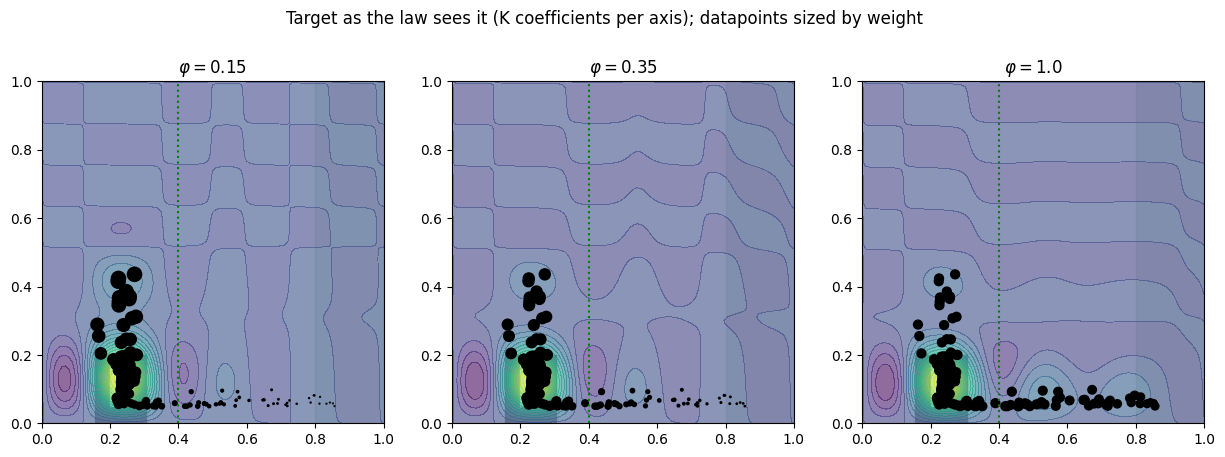

In [9]:
xa = np.linspace(0, WORLD, 101)
norms = np.where(np.arange(K) == 0, L, L / 2)


# The density the K^d coefficients describe, on the grid xa x xa, indexed [x2, x1].
def density(ttW):
    B = np.array([Phi(u) for u in xa]) / norms
    return (B @ ttW.full().reshape(K, K) @ B.T).T


fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, phi in zip(ax, (0.15, 0.35, 1.0), strict=True):
    draw_world(a, Slide())
    a.contourf(xa, xa, density(target(weights(phi))), levels=20, alpha=0.6)
    a.scatter(*X_p.T, s=40 * N_P * weights(phi), c="k")
    a.set_title(rf"$\varphi = {phi}$")
fig.suptitle("Target as the law sees it (K coefficients per axis); datapoints sized by weight")
plt.show()

### Weights of the ergodic metric
$$\mathbf{\Lambda}_{\mathbf{k}} = (1 + \|\mathbf{k}\|^2)^{-\frac{d+1}{2}}, \qquad \xi = \sum_{\mathbf{k}} \mathbf{\Lambda}_{\mathbf{k}} \big(\mathcal{W}_{\mathbf{k}} - \hat{\mathcal{W}}_{\mathbf{k}}\big)^2.$$
Built by TT-cross and TT-rounded, as in E2T2.

In [10]:
def Lambda_func(idx):  # multi-indices k (M, d) -> (M,)
    return (1.0 + np.linalg.norm(idx.reshape(-1, d), axis=1) ** 2) ** (-(d + 1) / 2)


ttLambda = rect_cross(Lambda_func, x0=tt.rand(K, d, r=1), nswp=15, kickrank=1, eps=1e-4)
ttLambda = ttLambda.round(1e-2)
print("Rank of ttLambda:", ttLambda.r)

Rank of ttLambda: [1 3 1]


### Spatial statistic with forgetting
E2T2's time average $\mathcal{W}(t) = \frac{1}{t}\int_0^t \mathbf{\Phi}(\mathbf{x}(\tau))\,d\tau$ weighs the first second of a run as much as the last, so coverage once gained is never lost. With forgetting it becomes a normalised, exponentially weighted average:
$$\mathbf{A}(\ell) = \lambda\, \mathbf{A}(\ell - 1) + \Delta t\, \mathbf{\Phi}(\mathbf{x}_\ell), \qquad Z(\ell) = \lambda\, Z(\ell - 1) + \Delta t, \qquad \mathcal{W}(\ell) = \frac{\mathbf{A}(\ell)}{Z(\ell)}, \qquad \lambda = e^{-\Delta t / T_{\mathrm{f}}}.$$
$\lambda = 1$ is E2T2's average exactly. The horizon's half-life is the master's duration, the time one pass along it takes at full speed: when such a pass ends, its start still holds half its weight,
$$T_{\mathrm{f}} = \frac{S_{\mathrm{m}} / u_{\max}}{\ln 2}.$$ Scaling a TT by $\lambda$ is exact and keeps its rank; only the added rank-1 $\mathbf{\Phi}$ raises it, so $\mathbf{A}$ is TT-rounded every `FLUSH` steps, as in E2T2.

In [11]:
T_F = (S_m / (V_MAX / DT)) / np.log(2)  # s
FLUSH = 5
RMAX = K ** (d // 2)  # the highest rank a TT of K^d entries can have: rounding loses only eps


@dataclass
class Statistic:
    lam: float  # forgetting factor per step; 1 is E2T2's time average
    ttA: tt.vector = None
    Z: float = 0.0
    n: int = 0

    def add(self, tt_phi):
        self.ttA = tt_phi * DT if self.ttA is None else self.ttA * self.lam + tt_phi * DT
        self.Z, self.n = self.lam * self.Z + DT, self.n + 1
        if self.n % FLUSH == 0:
            self.ttA = self.ttA.round(1e-6, RMAX)

    def W(self):
        return self.ttA * (1 / self.Z)


lam_f = np.exp(-DT / T_F)
print(f"T_f = {T_F:.2f} s, lambda = {lam_f:.5f}")

T_f = 3.64 s, lambda = 0.99726


### Phase
The target needs to know how far the task has come. The phase $\tilde{\varphi}$ is the posterior mean of a Bayesian filter over the master's samples, with belief $\beta_\ell(a)$:
$$\beta_\ell(a) \propto \mathcal{N}(\mathbf{x}_\ell;\, \mathbf{m}_a,\, h^2 \mathbf{I}) \sum_{a'} \mathcal{N}(s_a - s_{a'};\, 0,\, \sigma_\ell^2)\, \beta_{\ell-1}(a'), \qquad \sigma_\ell = \max\big(\|\mathbf{x}_\ell - \mathbf{x}_{\ell-1}\|,\ S_{\mathrm{m}} / N_{\mathrm{m}}\big), \qquad \tilde{\varphi}_\ell = \sum_a \beta_\ell(a)\, \varphi_a,$$
where $s_a$ is the arc length of sample $a$. The transition is a random walk in arc length as wide as the tip actually moved, since the position along the master cannot change by more than that; it is symmetric, so it assumes no direction of progress and the phase may fall. The likelihood uses the target's own kernel width $h$. The first belief is the likelihood alone. The update runs in log space over every pair of samples, so a tip far from where the belief sits cannot underflow it to zero.

In [12]:
ARC2 = (s_grid[:, None] - s_grid[None]) ** 2  # squared arc-length distances between samples


@dataclass
class PhaseFilter:
    log_belief: np.ndarray = None
    x_prev: np.ndarray = None

    def update(self, x):  # -> the posterior mean phase
        log_lik = -((master - x) ** 2).sum(axis=1) / (2 * h**2)
        if self.log_belief is None:
            log_belief = log_lik
        else:
            sigma = max(np.linalg.norm(x - self.x_prev), S_m / N_M)
            log_belief = logsumexp(self.log_belief[None] - ARC2 / (2 * sigma**2), axis=1) + log_lik
        self.log_belief = log_belief - logsumexp(log_belief)
        self.x_prev = x
        return float(np.exp(self.log_belief) @ phi_master)

### One trial
Each step, at the measured state $\mathbf{x}_\ell$: the phase $\tilde{\varphi}_\ell$, the target $\hat{\mathcal{W}}(\tilde{\varphi}_\ell)$, the statistic with $\mathbf{\Phi}(\mathbf{x}_\ell)$ added, and the direction (E2T2, Eq. (4))
$$b_i = \sum_{\mathbf{k}} \mathbf{\Lambda}_{\mathbf{k}} \big(\mathcal{W}_{\mathbf{k}} - \hat{\mathcal{W}}_{\mathbf{k}}(\tilde{\varphi})\big) \nabla_i \mathbf{\Phi}_{\mathbf{k}}(\mathbf{x}_\ell), \qquad \mathbf{x}_{\ell+1} = \mathrm{step}\Big(\mathbf{x}_\ell,\ \mathbf{x}_\ell - u_{\max} \Delta t\, \frac{\mathbf{b}}{\|\mathbf{b}\|} + \boldsymbol{\nu}_\ell\Big),$$
with $\boldsymbol{\nu}_\ell$ the actuator noise and `step` the world. The minus sign is missing in the paper's Eq. (4) but needed, as the E2T2 code has it. E2T2 itself is the static target with $\lambda = 1$. A trial starts at the master's start and ends at the goal, or after `MAX_STEPS`; the statistic is passed in, so a sequence of trials can hand it on.

In [13]:
MAX_STEPS = 5000
STATIC = target(np.full(N_P, 1 / N_P))


def run_trial(world, stat, expanding, rng):
    x, filt = MASTER[0].copy(), PhaseFilter()
    path, phis, dead = [x], [], [in_dead_end(world, x)]
    for _ in range(MAX_STEPS):
        phi = filt.update(x)
        tt_phi, tt_dphi = tt_phi_dphi(x)
        stat.add(tt_phi)
        ttW_hat = target(weights(phi)) if expanding else STATIC
        ttVdW = ttLambda * (stat.W() - ttW_hat)
        b = np.array([tt.dot(ttVdW, tt_dphi[i]) for i in range(d)])
        x = step(world, x, x - V_MAX * b / np.linalg.norm(b) + rng.uniform(-NOISE, NOISE, d))
        path.append(x)
        phis.append(phi)
        dead.append(in_dead_end(world, x))
        if succeeded(world, x):
            break
    dead = np.array(dead)
    return {
        "path": np.array(path),
        "phi": np.array(phis),
        "steps": len(phis),
        "success": succeeded(world, x),
        "dead_ends": int((dead[1:] & ~dead[:-1]).sum()),
        "inserted": not world.barrier,  # a failure that inserted is a slip-out, one that did not never inserted
        "dead_share": float(dead.mean()),
    }

### One trial in the taught world
The expanding law with forgetting, and E2T2 for comparison: the path coloured by phase, and the phase over the trial.

A trial that inserts but leaves the slot mid-push does not recover: the target is fixed in the world, so it sends the tip back to where the slot was taught. That is the week-6 limit of a world-frame target, out of scope here, and counted as its own failure.

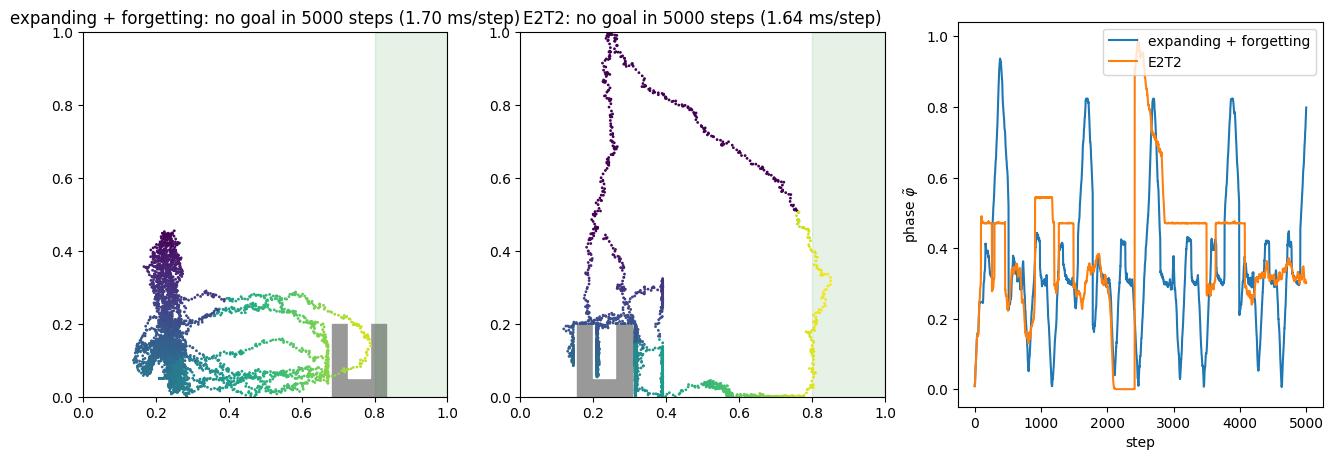

In [14]:
fig, ax = plt.subplots(1, 3, figsize=(16, 5))
for a, (name, expanding, lam) in zip(
    ax[:2], (("expanding + forgetting", True, lam_f), ("E2T2", False, 1.0)), strict=True
):
    world = Slide()
    t0 = time.time()
    r = run_trial(world, Statistic(lam), expanding, np.random.default_rng(0))
    draw_world(a, world)
    a.scatter(*r["path"][1:].T, c=r["phi"], s=1, vmin=0, vmax=1)
    a.set_title(
        f"{name}: {'goal' if r['success'] else 'no goal'} in {r['steps']} steps ({1e3 * (time.time() - t0) / r['steps']:.2f} ms/step)"
    )
    ax[2].plot(r["phi"], label=name)
ax[2].set(xlabel="step", ylabel=r"phase $\tilde\varphi$")
ax[2].legend()
plt.show()

### One trial with the block displaced
The block $0.09$ to either side of where it was taught, so the taught descent lands beside it. The expanding law with forgetting, and E2T2, on the same noise.

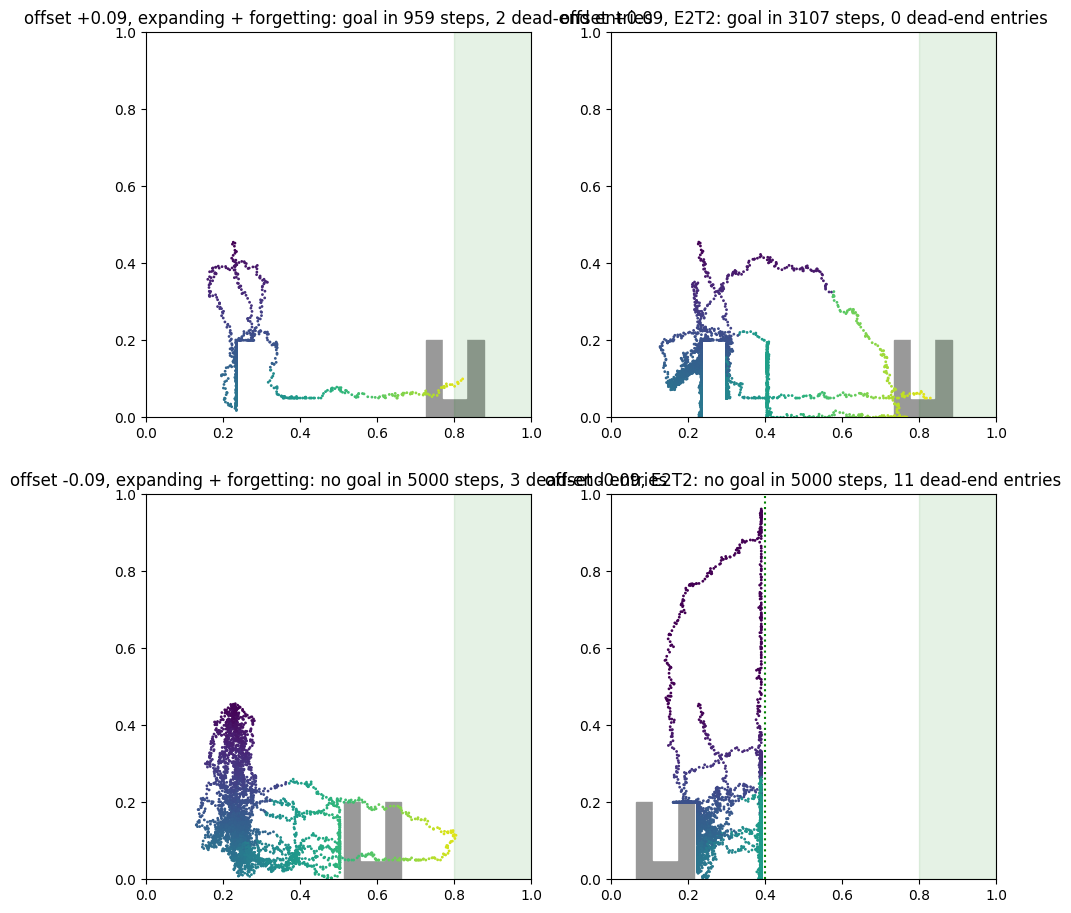

In [15]:
fig, ax = plt.subplots(2, 2, figsize=(11, 11))
for row, offset in zip(ax, (0.09, -0.09), strict=True):
    for a, (name, expanding, lam) in zip(
        row, (("expanding + forgetting", True, lam_f), ("E2T2", False, 1.0)), strict=True
    ):
        world = Slide(offset)
        r = run_trial(world, Statistic(lam), expanding, np.random.default_rng(1))
        draw_world(a, world)
        a.scatter(*r["path"][1:].T, c=r["phi"], s=1, vmin=0, vmax=1)
        a.set_title(
            f"offset {offset:+.2f}, {name}: {'goal' if r['success'] else 'no goal'} in {r['steps']} steps, {r['dead_ends']} dead-end entries"
        )
plt.show()

### A sequence of trials
As in E2T2, a trial ends at the goal or after `MAX_STEPS`, and the next one starts at the master's start with the block back where the sequence put it. Only the state and the world are reset: the statistic is handed on, since the paper's re-initialisation is instantaneous. The noise of trial $c$ in sequence $s$ is seeded by $(s, c)$, so every setting sees the same noise. The experiments are in `Sequential_E2T2_peg_slide_2D_experiments.ipynb`.

In [16]:
METHODS = {  # name -> (expanding, lambda)
    "E2T2": (False, 1.0),
    "expanding + forgetting": (True, lam_f),
}


def run_sequence(expanding, lam, offset, seq, n_trials=10):
    stat = Statistic(lam)
    return [
        run_trial(Slide(offset), stat, expanding, np.random.default_rng([seq, c]))
        for c in range(n_trials)
    ]

### One sequence
The block $0.09$ to the left, each method: the paths of the expanding law by trial, and the steps per trial (a trial that fails counts `MAX_STEPS`).

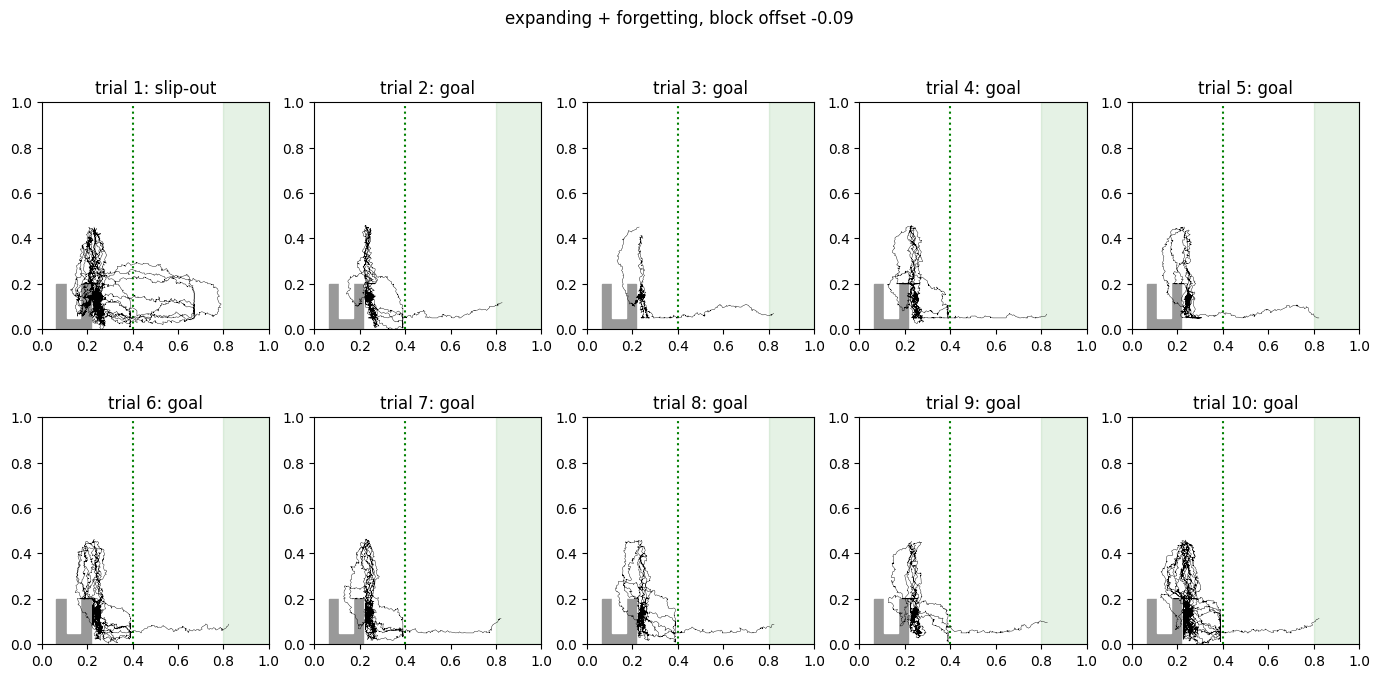

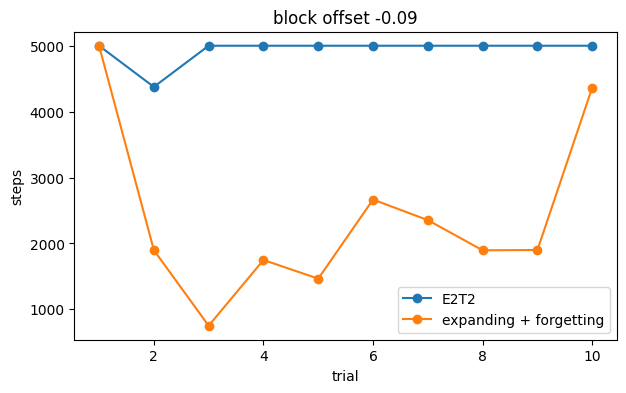

In [17]:
OFFSET = -0.09
with Pool(len(METHODS)) as pool:
    seq0 = dict(
        zip(
            METHODS,
            pool.starmap(run_sequence, [(*s, OFFSET, 0) for s in METHODS.values()]),
            strict=True,
        )
    )

fig, ax = plt.subplots(2, 5, figsize=(17, 7.5))
for c, a in enumerate(ax.flat):
    r = seq0["expanding + forgetting"][c]
    draw_world(a, Slide(OFFSET))
    a.plot(*r["path"].T, "k", lw=0.3)
    outcome = "goal" if r["success"] else "slip-out" if r["inserted"] else "never inserted"
    a.set_title(f"trial {c + 1}: {outcome}")
fig.suptitle(f"expanding + forgetting, block offset {OFFSET:+.2f}")
plt.show()

fig, a = plt.subplots(figsize=(7, 4))
for m, trials in seq0.items():
    a.plot(range(1, len(trials) + 1), [r["steps"] for r in trials], "o-", label=m)
a.set(xlabel="trial", ylabel="steps", title=f"block offset {OFFSET:+.2f}")
a.legend()
plt.show()

## Checks
Each compares against an independent computation, not against a printed value.

**Basis gradient**: $\nabla_i \mathbf{\Phi}$ from `tt_phi_dphi` against a central difference of $\mathbf{\Phi}$.

In [18]:
x_c, eps = np.array([0.37, 0.81]), 1e-6
for i in range(d):
    e = eps * np.eye(d)[i]
    fd = (tt_phi_dphi(x_c + e)[0].full() - tt_phi_dphi(x_c - e)[0].full()) / (2 * eps)
    print(f"axis {i}: max |grad - fd| =", np.abs(tt_phi_dphi(x_c)[1][i].full() - fd).max())

axis 0: max |grad - fd| = 3.3292657519723434e-09
axis 1: max |grad - fd| = 1.456104570252137e-09


**Environment**: rigid replays of the master. In the taught world it reaches the goal; with the block $0.05$ to either side it lands on the block's top and stays there; pushing the block before the insertion, from inside the slot or from beside the block, ends at the barrier or at the block.

In [19]:
for offset in (0.0, 0.05, -0.05):
    world = Slide(offset)
    s = replay(world, MASTER, 3000)[-1]
    print(f"offset {offset:+.2f}: succeeded {succeeded(world, s)}, tip {s.round(3)}")
    assert succeeded(world, s) == (offset == 0.0)
    assert offset == 0.0 or abs(s[1] - BLOCK_TOP) < 1e-9

world = Slide()
shallow = np.array([[C0, 0.45], [C0, 0.10], [0.85, 0.10]])  # into the slot, not to its floor
s = replay(world, shallow, 3000)[-1]
print(f"push without full insertion: block at {world.c:.3f}, barrier {world.barrier}")
assert world.barrier and world.c == BARRIER_X - PEG - BLOCK_HALF

world = Slide()
s = replay(world, np.array([[0.05, 0.05], [0.85, 0.05]]), 3000)[-1]
print(
    f"push from beside the block: tip x {s[0]:.3f}, block at {world.c:.3f}, dead end {in_dead_end(world, s)}"
)
assert world.c == C0 and in_dead_end(world, s)

offset +0.00: succeeded True, tip [0.85 0.06]


offset +0.05: succeeded False, tip [0.23 0.2 ]


offset -0.05: succeeded False, tip [0.23 0.2 ]
push without full insertion: block at 0.315, barrier True


push from beside the block: tip x 0.145, block at 0.230, dead end True


**Kernel target**: the closed form against E2T2's route, TT-cross of the kernel density on a Gauss-Legendre grid, at $\varphi = 0.35$. The density must have mass 1 inside the cube and the coefficients must agree to quadrature accuracy.

In [20]:
w_chk = weights(0.35)


def p_chk(x):  # (M, d) -> (M,): the kernel density with weights w_chk
    return np.prod([g(x[:, None, i], X_p[None, :, i], h) for i in range(d)], axis=0) @ w_chk


N = int(np.ceil(4 * L / h))  # quadrature nodes per axis, a few per kernel width
x0, w0 = np.polynomial.legendre.leggauss(N)
xn, wn = CUBE_LO + 0.5 * L * (x0 + 1.0), 0.5 * L * w0
ttP = rect_cross(
    lambda idx: np.prod(wn[idx.astype(int)], axis=1) * p_chk(xn[idx.astype(int)]),
    x0=tt.rand(N, d, r=1),
    nswp=30,
    kickrank=1,
    eps=1e-8,
    verbose=False,
)
ones = tt.vector.from_list([np.ones(N).reshape(1, -1, 1)] * d)
phi_all = np.cos(np.pi * (xn[:, None] - CUBE_LO) * np.arange(K) / L)
ttW_cross = tt.vector.from_list(
    [np.einsum("anb,nk->akb", c, phi_all) for c in tt.vector.to_list(ttP)]
)
err = np.abs(ttW_cross.full() - target(w_chk).full()).max()
print(
    f"N = {N}: mass inside the cube {tt.dot(ones, ttP):.12f}, max |W_cross - W_closed| = {err:.2e}"
)

N = 364: mass inside the cube 0.999999999906, max |W_cross - W_closed| = 4.57e-10


**Forgetting statistic**: the TT accumulator against the dense recursion $\mathbf{A} \leftarrow \lambda \mathbf{A} + \Delta t\, \mathbf{\Phi}(\mathbf{x})$ on a random walk of 2000 steps, on every one of the $K^d$ coefficients, with forgetting and without.

In [21]:
walk = np.clip(
    0.5 + np.cumsum(np.random.default_rng(2).uniform(-V_MAX, V_MAX, (2000, d)), axis=0), 0.0, WORLD
)
for lam in (lam_f, 1.0):
    stat, A, Z = Statistic(lam), np.zeros((K, K)), 0.0
    for x_ in walk:
        stat.add(tt_phi_dphi(x_)[0])
        A, Z = lam * A + DT * np.outer(Phi(x_[0]), Phi(x_[1])), lam * Z + DT
    err = np.abs(stat.W().full() - A / Z).max() / np.abs(A / Z).max()
    print(
        f"lambda = {lam:.5f}: Z = {stat.Z:.4f} (dense {Z:.4f}), max relative |W_tt - W_dense| = {err:.1e}"
    )

lambda = 0.99726: Z = 3.6328 (dense 3.6328), max relative |W_tt - W_dense| = 7.3e-07


lambda = 1.00000: Z = 20.0000 (dense 20.0000), max relative |W_tt - W_dense| = 5.3e-06


**Phase filter**: on the master replayed without noise its phase rises with the arc length and never falls by more than one sample; on a replay that goes down into the slot and back up to the start it falls back.

In [22]:
world = Slide()
path_ = replay(world, MASTER, 3000)
filt = PhaseFilter()
phi_ = np.array([filt.update(x_) for x_ in path_])
true_ = phase_label(path_)
print(
    f"along the master: largest fall {max(0.0, -np.diff(phi_).min()):.1e}, max |phase - arc length| {np.abs(phi_ - true_).max():.4f}"
)
assert -np.diff(phi_).min() < 1 / N_M

filt = PhaseFilter()
back = replay(Slide(), np.array([MASTER[0], MASTER[1], MASTER[0]]), 3000)
phi_ = np.array([filt.update(x_) for x_ in back])
print(f"down and back up: peak {phi_.max():.3f}, end {phi_[-1]:.3f}")
assert phi_.max() > 0.35 and phi_[-1] < 0.02

along the master: largest fall 1.1e-03, max |phase - arc length| 0.0143


down and back up: peak 0.379, end 0.010
